# 07 — Avaliação Final, Interpretação e Justiça

Chegamos ao fim da trilha. Ao longo dos notebooks 02 a 06, tomamos todas as decisões **só com validação cruzada no treino**:
- **Pré-processamento** (notebook 03): para o gradient boosting, nenhum; ele entende as categorias e os ausentes sozinho.
- **Modelo** (notebook 05): `HistGradientBoostingClassifier` com as configurações padrão, a melhor AUC (0,929).
- **Probabilidades** (notebook 06): bem calibradas, sem pesos de classe.
- **Limiar** (notebook 04): ajustado para o F1 com o `TunedThresholdClassifierCV`.

Neste notebook vamos:
- Treinar o **modelo final** e avaliá-lo, **uma única vez**, no **conjunto de teste** guardado desde o notebook 02
- Ver **o que o modelo usa** para decidir (*permutation importance*)
- **Medir a justiça** (*fairness*) do modelo entre homens e mulheres e entre raças, como prometido no notebook 01
- Testar se **remover a coluna `sex`** resolve o problema
- **Salvar** o modelo e usá-lo para pessoas novas
- Discutir as **limitações** e o **uso responsável**

> Este notebook leva cerca de **30 segundos** para rodar.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance   # já conhecida do ML-01 (notebook 07)

# Ferramentas novas deste notebook:
from pathlib import Path   # manipula caminhos de pastas e arquivos
import joblib              # salva e carrega modelos (como no ML-01)

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
colunas = colunas_numericas + colunas_categoricas

## 2. O modelo final e a estimativa da validação cruzada

Antes de abrir o teste, vamos registrar o que a validação cruzada **prevê** para o modelo final. Como o limiar é escolhido por uma validação cruzada **interna**, usamos a validação cruzada **aninhada** do notebook 04: o limiar é escolhido de novo em cada dobra, sem nunca olhar para a dobra de validação.

In [2]:
# O modelo final: gradient boosting padrão + limiar ajustado para o F1.
modelo_final = TunedThresholdClassifierCV(
    HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42),
    scoring="f1",
    cv=cv,
)

# ⏱️ ~15 segundos: 5 dobras de fora × 5 dobras internas.
metricas_cv = ["roc_auc", "accuracy", "precision", "recall", "f1"]
cv_resultado = cross_validate(modelo_final, X_train[colunas], y_train, cv=cv, scoring=metricas_cv)

estimativa_cv = pd.DataFrame({
    "média": {m: cv_resultado[f"test_{m}"].mean() for m in metricas_cv},
    "± desvio": {m: cv_resultado[f"test_{m}"].std() for m in metricas_cv},
})
estimativa_cv

,média,± desvio
roc_auc,0.9285,0.0029
accuracy,0.8641,0.0049
precision,0.7002,0.0137
recall,0.7563,0.0156
f1,0.7270,0.0088


In [3]:
# Agora sim: treinamos o modelo final com TODO o treino.
modelo_final.fit(X_train[colunas], y_train)
print(f"Limiar escolhido: {modelo_final.best_threshold_:.3f}")

Limiar escolhido: 0.404


**Conclusão:** a validação cruzada aninhada prevê, para o modelo final, **AUC de 0,9285 ± 0,0029** e **F1 de 0,727 ± 0,009**, com precisão de 70,0% e recall de 75,6%. Treinado com todo o treino, o modelo escolheu o limiar **0,404**, perto dos ~0,39 que o boosting tinha no notebook 06. São esses os números que o teste vai confirmar (ou não).

## 3. A avaliação final no teste

Este é o momento que esperamos desde o notebook 02. O teste tem **9.769 pessoas** que nenhum modelo, nenhuma decisão e nenhum gráfico usou até agora. O resultado aqui é a melhor estimativa de como o modelo se sairia com **pessoas novas**.

In [4]:
prob_teste = modelo_final.predict_proba(X_test[colunas])[:, 1]
previsao_teste = modelo_final.predict(X_test[colunas])   # já usa o limiar ajustado

resultado_teste = {
    "roc_auc": roc_auc_score(y_test, prob_teste),
    "accuracy": accuracy_score(y_test, previsao_teste),
    "precision": precision_score(y_test, previsao_teste),
    "recall": recall_score(y_test, previsao_teste),
    "f1": f1_score(y_test, previsao_teste),
}
comparacao = estimativa_cv.copy()
comparacao["teste"] = pd.Series(resultado_teste)
# A diferença em "desvios padrão": quantos desvios o teste ficou longe da média da validação cruzada.
comparacao["diferença (em desvios)"] = (comparacao["teste"] - comparacao["média"]) / comparacao["± desvio"]
comparacao.index = ["AUC", "acurácia", "precisão", "recall", "F1"]
comparacao

,média,± desvio,teste,diferença (em desvios)
AUC,0.9285,0.0029,0.9298,0.4561
acurácia,0.8641,0.0049,0.8704,1.2827
precisão,0.7002,0.0137,0.7269,1.9589
recall,0.7563,0.0156,0.7344,-1.4105
F1,0.7270,0.0088,0.7306,0.4141


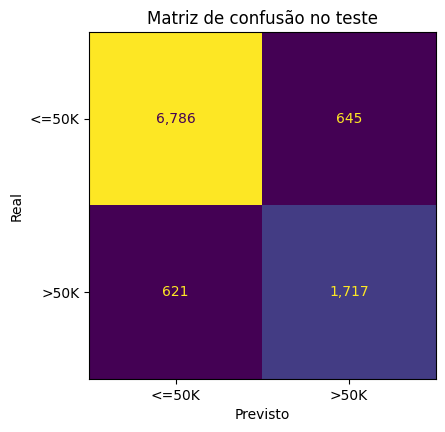

Log loss no teste: 0.2735


In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, previsao_teste, display_labels=["<=50K", ">50K"], values_format=",", colorbar=False, ax=ax
)
ax.set_title("Matriz de confusão no teste")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
plt.show()

print(f"Log loss no teste: {log_loss(y_test, prob_teste):.4f}")

**Conclusão:** o teste **confirmou** as estimativas da validação cruzada:
- **AUC de 0,930** e **F1 de 0,731**, contra 0,9285 e 0,727 previstos. As duas ficaram a menos de meio desvio padrão da estimativa.
- Todas as métricas ficaram a **menos de 2 desvios padrão** da validação cruzada. A maior diferença foi a precisão (72,7% no teste contra 70,0%), compensada por um recall um pouco menor (73,4% contra 75,6%): o equilíbrio entre os dois mudou um pouco, mas o F1, que combina os dois, ficou praticamente igual.
- A **matriz de confusão** mostra que, das 2.338 pessoas de renda alta do teste, o modelo encontrou **1.717** e deixou escapar 621. Das 2.362 pessoas que ele apontou como `>50K`, 645 foram alarmes falsos.
- A **log loss** no teste (0,274) também bate com a da validação cruzada (0,277 no notebook 06): as probabilidades continuam bem calibradas em pessoas novas.

Como não tomamos **nenhuma** decisão olhando para o teste, esse resultado é uma estimativa honesta de como o modelo se sairia com pessoas novas (do mesmo censo de 1994).

## 4. A evolução ao longo da trilha

Para ver o caminho percorrido, vamos treinar os modelos de cada etapa com todo o treino e avaliá-los no teste. Como o modelo final já foi escolhido, isso não influencia mais nenhuma decisão: é só para registrar a evolução.

In [6]:
logistica_completa = Pipeline([
    ("preparar", ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", Pipeline([
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), colunas_categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

# (nome, modelo, colunas usadas)
etapas = [
    ("Baseline: sempre <=50K (nb 02)", DummyClassifier(strategy="most_frequent"), colunas_numericas),
    ("Logística só numéricas (nb 02)", Pipeline([("padronizar", StandardScaler()), ("modelo", LogisticRegression())]),
     colunas_numericas),
    ("Logística + categóricas (nb 03)", logistica_completa, colunas),
    ("Logística + limiar ajustado (nb 04)", TunedThresholdClassifierCV(logistica_completa, scoring="f1", cv=cv), colunas),
    ("Gradient boosting (nb 05)", HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42),
     colunas),
]

evolucao = {}
for nome, modelo, cols in etapas:
    modelo.fit(X_train[cols], y_train)
    previsto = modelo.predict(X_test[cols])
    evolucao[nome] = {
        "AUC": roc_auc_score(y_test, modelo.predict_proba(X_test[cols])[:, 1]),
        "acurácia": accuracy_score(y_test, previsto),
        "precisão": precision_score(y_test, previsto, zero_division=0),
        "recall": recall_score(y_test, previsto),
        "F1": f1_score(y_test, previsto),
    }
evolucao["Boosting + limiar ajustado (FINAL)"] = {
    "AUC": resultado_teste["roc_auc"], "acurácia": resultado_teste["accuracy"],
    "precisão": resultado_teste["precision"], "recall": resultado_teste["recall"], "F1": resultado_teste["f1"],
}
tabela_evolucao = pd.DataFrame(evolucao).T
tabela_evolucao

,AUC,acurácia,precisão,recall,F1
Baseline: sempre <=50K (nb 02),0.5000,0.7607,0.0000,0.0000,0.0000
Logística só numéricas (nb 02),0.8321,0.8193,0.7320,0.3867,0.5060
Logística + categóricas (nb 03),0.9049,0.8554,0.7456,0.6005,0.6652
Logística + limiar ajustado (nb 04),0.9049,0.8379,0.6350,0.7583,0.6912
Gradient boosting (nb 05),0.9298,0.8755,0.7892,0.6548,0.7158
Boosting + limiar ajustado (FINAL),0.9298,0.8704,0.7269,0.7344,0.7306


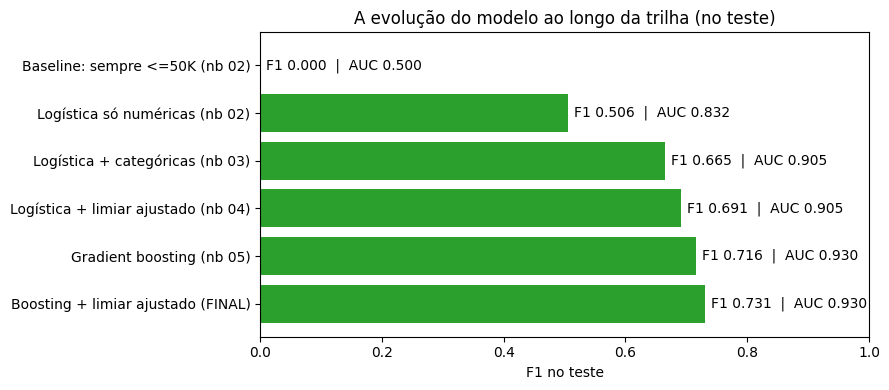

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabela_evolucao.index, tabela_evolucao["F1"], color="tab:green")
for i, (f1, auc) in enumerate(zip(tabela_evolucao["F1"], tabela_evolucao["AUC"])):
    ax.text(f1 + 0.01, i, f"F1 {f1:.3f}  |  AUC {auc:.3f}", va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("F1 no teste")
ax.set_title("A evolução do modelo ao longo da trilha (no teste)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Conclusão:** cada etapa da trilha trouxe um ganho real, agora confirmado em dados que nenhum modelo viu:
- **Baseline (nb 02):** acurácia de 76%, mas F1 **zero**: não encontra ninguém.
- **Logística com as numéricas (nb 02):** AUC 0,832, F1 0,506. Encontrava só 39% das pessoas de renda alta.
- **One-hot das categóricas (nb 03):** o maior salto da trilha. A AUC foi para **0,905**, e o F1, para 0,665.
- **Limiar ajustado (nb 04):** a AUC não muda (o modelo é o mesmo), mas o F1 sobe para **0,691** e o recall vai de 60% para 76%, em troca de uma acurácia menor.
- **Gradient boosting (nb 05):** AUC **0,930**, o segundo maior salto. Com o limiar ajustado, o F1 chega a **0,731**.

Repare na acurácia: o modelo de maior acurácia (87,55%) é o boosting **sem** ajuste de limiar, e não o final (87,04%). Escolhemos o limiar pelo F1, que valoriza encontrar as pessoas de renda alta, e não pela acurácia. É a lição do notebook 04: a métrica certa depende do objetivo.

## 🎓 Conceito: permutation importance (relembrando)

No ML-01 (notebook 07), aprendemos a **permutation importance**: embaralhar uma coluna de cada vez e medir **quanto o desempenho piora**. Se embaralhar uma coluna derruba a métrica, o modelo depende muito dela; se não muda nada, ela é dispensável.

Aqui, medimos a piora na **AUC** do teste. Embaralhamos cada coluna 10 vezes e tiramos a média, para reduzir o efeito do acaso.

⚠️ Lembre do aviso do ML-01: quando duas colunas carregam a **mesma informação** (como `marital-status` e `relationship`), embaralhar só uma delas pode parecer inofensivo, porque o modelo ainda tem a outra. A importância delas fica **dividida**, e cada uma parece menos importante do que a informação realmente é.

## 5. O que o modelo usa para decidir?

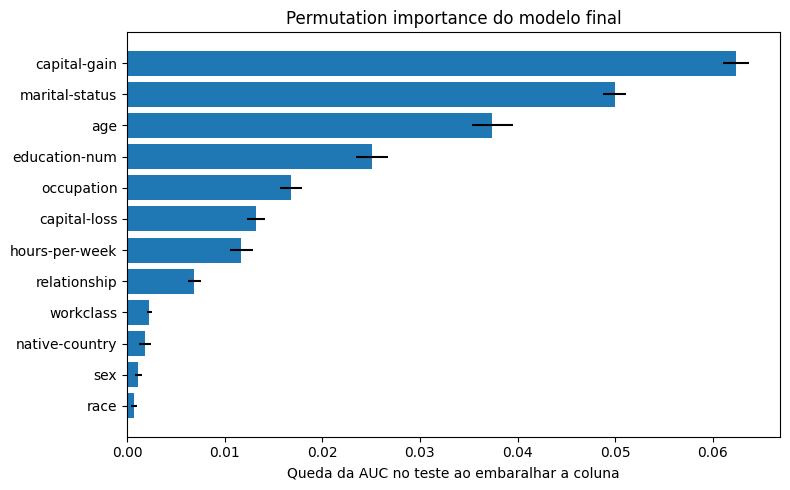

,queda média da AUC,± desvio
capital-gain,0.0624,0.0013
marital-status,0.0499,0.0012
age,0.0374,0.0021
education-num,0.0251,0.0017
occupation,0.0168,0.0011
capital-loss,0.0132,0.0009
hours-per-week,0.0117,0.0012
relationship,0.0069,0.0007
workclass,0.0023,0.0003
native-country,0.0018,0.0006


In [8]:
importancia = permutation_importance(
    modelo_final, X_test[colunas], y_test,
    scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1,
)
tabela_importancia = pd.DataFrame({
    "queda média da AUC": importancia.importances_mean,
    "± desvio": importancia.importances_std,
}, index=colunas).sort_values("queda média da AUC")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabela_importancia.index, tabela_importancia["queda média da AUC"],
        xerr=tabela_importancia["± desvio"])   # xerr desenha uma barrinha de erro com o desvio
ax.set_xlabel("Queda da AUC no teste ao embaralhar a coluna")
ax.set_title("Permutation importance do modelo final")
plt.tight_layout()
plt.show()

tabela_importancia.sort_values("queda média da AUC", ascending=False)

**Conclusão:** - **`capital-gain` é a coluna mais importante:** embaralhá-la derruba a AUC em **0,062**. É o "degrau" que vimos nos notebooks 03 e 05: um ganho alto é quase uma garantia de renda alta.
- **`marital-status` (0,050)**, **`age` (0,037)** e **`education-num` (0,025)** vêm em seguida, exatamente as relações mais fortes da análise exploratória.
- **`relationship` parece pouco importante (0,007)**, mas é o efeito da informação **dividida** do aviso acima: ela repete o estado civil (e o sexo). Com `marital-status` disponível, embaralhar `relationship` faz pouca falta.
- **`sex` (0,0012)** e **`race` (0,0007)** aparecem entre as menos importantes. Mas cuidado: isso **não** significa que o modelo é neutro em relação a elas. Como veremos agora, o sexo está "escondido" em outras colunas.

## 🎓 Conceito: justiça em Machine Learning (fairness)

No notebook 01, vimos que, nos dados de 1994, **30%** dos homens e só **11%** das mulheres ganhavam mais de 50 mil. Um modelo treinado com esses dados **aprende** essa diferença. A pergunta de *fairness* é: **o modelo trata os grupos de forma justa?**

O problema é que "justo" pode significar coisas diferentes, e cada significado vira uma métrica diferente, calculada **separadamente para cada grupo**:

| Critério | Pergunta | Métrica comparada entre os grupos |
|---|---|---|
| **Paridade demográfica** | O modelo aponta a mesma proporção de pessoas de cada grupo? | **Taxa de seleção**: % apontados como `>50K` |
| **Igualdade de oportunidade** | Entre quem **realmente** tem renda alta, o modelo encontra a mesma proporção em cada grupo? | **Recall** |
| **Mesma taxa de alarmes falsos** | Entre quem **não** tem renda alta, o modelo erra igualmente em cada grupo? | **Taxa de falsos positivos** |
| **Calibração por grupo** | Um "70%" significa o mesmo para homens e para mulheres? | **Probabilidade média** × **taxa real** |

Um resultado importante da área: quando os grupos têm **taxas reais diferentes** (11% × 30%), é **matematicamente impossível** satisfazer todos esses critérios ao mesmo tempo (exceto com um modelo perfeito). Escolher qual critério priorizar é uma decisão **ética e de negócio**, não técnica.

Analogia: uma escola com duas turmas, uma com média 9 e outra com média 6 nas provas anteriores. "Aprovar a mesma proporção em cada turma" e "aplicar exatamente o mesmo critério de nota a todos" são duas ideias razoáveis de justiça, e elas se contradizem.

## 6. Medindo a justiça por sexo

In [9]:
def metricas_por_grupo(coluna, y_real, probs, previstos, X_ref):
    """Calcula, para cada grupo de uma coluna, as métricas de fairness da tabela acima."""
    linhas = {}
    # .cat.categories: as categorias possíveis de uma coluna do tipo category.
    for grupo in X_ref[coluna].cat.categories:
        filtro = (X_ref[coluna] == grupo).to_numpy()   # to_numpy(): True/False sem o índice do pandas
        real, prob, prev = y_real.to_numpy()[filtro], probs[filtro], previstos[filtro]
        linhas[grupo] = {
            "pessoas": filtro.sum(),
            "taxa real": real.mean(),
            "prob. média": prob.mean(),
            "taxa de seleção": prev.mean(),
            "recall": recall_score(real, prev),
            "precisão": precision_score(real, prev, zero_division=0),
            "taxa de falsos positivos": prev[real == 0].mean(),   # entre os <=50K, quantos foram apontados
            "AUC": roc_auc_score(real, prob),
        }
    return pd.DataFrame(linhas).T


fairness_sexo = metricas_por_grupo("sex", y_test, prob_teste, previsao_teste, X_test)
fairness_sexo

,pessoas,taxa real,prob. média,taxa de seleção,recall,precisão,taxa de falsos positivos,AUC
Female,3259.0,0.1108,0.1134,0.0991,0.6593,0.7368,0.0293,0.9475
Male,6510.0,0.3037,0.3003,0.3132,0.7481,0.7254,0.1235,0.9122


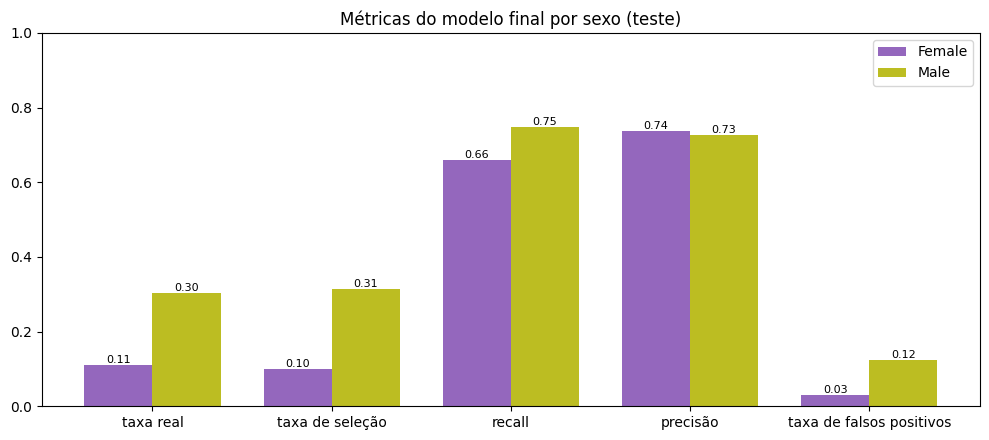

In [10]:
metricas_grafico = ["taxa real", "taxa de seleção", "recall", "precisão", "taxa de falsos positivos"]

fig, ax = plt.subplots(figsize=(10, 4.5))
posicoes = np.arange(len(metricas_grafico))
largura = 0.38
for deslocamento, (grupo, cor) in zip([-largura / 2, largura / 2], [("Female", "tab:purple"), ("Male", "tab:olive")]):
    valores = fairness_sexo.loc[grupo, metricas_grafico].astype(float)
    barras = ax.bar(posicoes + deslocamento, valores, width=largura, label=grupo, color=cor)
    ax.bar_label(barras, fmt="%.2f", fontsize=8)   # escreve o valor em cima de cada barra
ax.set_xticks(posicoes, metricas_grafico)
ax.set_ylim(0, 1)
ax.set_title("Métricas do modelo final por sexo (teste)")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** o modelo é **justo** por alguns critérios e **injusto** por outros, exatamente como a teoria previa:
- ✅ **Calibração por grupo:** a probabilidade média prevista bate com a taxa real nos dois grupos (11,3% contra 11,1% nas mulheres; 30,0% contra 30,4% nos homens). Um "70%" significa o mesmo para os dois.
- ✅ **Precisão parecida:** quando o modelo aponta alguém como `>50K`, ele acerta em 73,7% das mulheres e 72,5% dos homens.
- ❌ **Paridade demográfica:** o modelo aponta **31,3%** dos homens e só **9,9%** das mulheres como renda alta, **3 vezes mais** homens. Ele reproduz a diferença dos dados (30% × 11%).
- ❌ **Igualdade de oportunidade:** entre quem **realmente** tem renda alta, o modelo encontra **74,8%** dos homens e só **65,9%** das mulheres. Uma mulher de renda alta tem mais chance de **passar despercebida**.
- ⚠️ **Falsos positivos:** 12,4% dos homens de renda baixa são apontados por engano, contra 2,9% das mulheres. Aqui, o erro "favorece" os homens.

Na prática: se este modelo fosse usado para oferecer um produto financeiro, uma mulher qualificada teria **menos chance** de recebê-lo do que um homem igualmente qualificado (recall 66% × 75%), e um homem sem renda para isso receberia a oferta por engano com muito mais frequência.

## 7. Medindo a justiça por raça

In [11]:
fairness_raca = metricas_por_grupo("race", y_test, prob_teste, previsao_teste, X_test)
fairness_raca.sort_values("pessoas", ascending=False)

,pessoas,taxa real,prob. média,taxa de seleção,recall,precisão,taxa de falsos positivos,AUC
White,8312.0,0.2531,0.2524,0.2591,0.7429,0.7256,0.0952,0.9269
Black,968.0,0.1333,0.1265,0.1126,0.6434,0.7615,0.0310,0.9538
Asian-Pac-Islander,311.0,0.2637,0.2692,0.2862,0.7439,0.6854,0.1223,0.9000
Amer-Indian-Eskimo,96.0,0.1354,0.1163,0.0417,0.3077,1.0000,0.0000,0.9231
Other,82.0,0.1220,0.1182,0.0732,0.6000,1.0000,0.0000,0.9778


**Conclusão:** o padrão se repete por raça, mas aqui é preciso **cuidado com o tamanho dos grupos**:
- **Brancos** (8.312 pessoas) e **negros** (968) têm calibração boa (25,2% previsto × 25,3% real; 12,7% × 13,3%), mas o recall dos negros é bem menor: **64,3%**, contra 74,3% dos brancos.
- **Asiáticos** (311) têm taxas parecidas com as dos brancos.
- **Indígenas** (`Amer-Indian-Eskimo`, 96 pessoas) e **"outros"** (82) têm números extremos, como recall de 30,8% e precisão de 100%. Mas esses grupos têm só 13 e 10 pessoas de renda alta no teste: uma única pessoa a mais ou a menos muda o recall em 8 a 10 pontos. **Não dá para tirar conclusões firmes** com grupos tão pequenos, outro lembrete do aviso sobre categorias raras do notebook 01.

Grupos pequenos são um problema sério em fairness: são justamente os grupos para os quais o modelo tem menos dados para aprender, e para os quais temos menos dados para **medir** se ele é justo.

## 8. E se tirarmos a coluna `sex`?

Uma ideia intuitiva para tornar o modelo "justo" é simplesmente **não mostrar** o sexo a ele. No notebook 01, avisamos que isso provavelmente não resolveria, porque outras colunas carregam a mesma informação (`relationship` tem `Husband` e `Wife`). Vamos testar, sem usar o teste: com validação cruzada no treino, como toda decisão.

Comparamos três versões do boosting: com todas as colunas, sem `sex` e sem `sex` **nem** `relationship`. Para comparar só o efeito das colunas, usamos o mesmo limiar nas três (o escolhido pelo modelo final).

In [12]:
limiar = modelo_final.best_threshold_
versoes = {
    "Com todas as colunas": colunas,
    # list comprehension com "if": todas as colunas menos as indicadas.
    "Sem sex": [c for c in colunas if c != "sex"],
    "Sem sex e sem relationship": [c for c in colunas if c not in ["sex", "relationship"]],
}

resumo_versoes = {}
for nome, cols in versoes.items():
    prob = cross_val_predict(
        HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42),
        X_train[cols], y_train, cv=cv, method="predict_proba",
    )[:, 1]
    prev = (prob >= limiar).astype(int)
    # Usamos X_train (com todas as colunas) só para saber o sexo de cada pessoa na hora de separar os grupos.
    por_sexo = metricas_por_grupo("sex", y_train, prob, prev, X_train)
    resumo_versoes[nome] = {
        "AUC geral": roc_auc_score(y_train, prob),
        "seleção mulheres": por_sexo.loc["Female", "taxa de seleção"],
        "seleção homens": por_sexo.loc["Male", "taxa de seleção"],
        "recall mulheres": por_sexo.loc["Female", "recall"],
        "recall homens": por_sexo.loc["Male", "recall"],
        "falsos positivos mulheres": por_sexo.loc["Female", "taxa de falsos positivos"],
        "falsos positivos homens": por_sexo.loc["Male", "taxa de falsos positivos"],
    }

pd.DataFrame(resumo_versoes).T

,AUC geral,seleção mulheres,seleção homens,recall mulheres,recall homens,falsos positivos mulheres,falsos positivos homens
Com todas as colunas,0.9284,0.0970,0.3171,0.6513,0.7491,0.0292,0.1286
Sem sex,0.9278,0.1001,0.3158,0.6634,0.7452,0.0312,0.1284
Sem sex e sem relationship,0.9272,0.0938,0.3199,0.6321,0.7508,0.0280,0.1318


**Conclusão:** **tirar a coluna `sex` não resolveu nada**, como o notebook 01 suspeitava:
- **Sem `sex`:** a AUC quase não mudou (0,9284 → 0,9278), e a diferença entre os grupos continua a mesma: o modelo aponta 10,0% das mulheres e 31,6% dos homens, com recall de 66,3% contra 74,5%.
- **Sem `sex` e sem `relationship`:** de novo, quase nada muda. A seleção fica em 9,4% × 32,0%, e o recall em 63,2% × 75,1%.

Por quê? Porque o modelo **não precisa** da coluna `sex` para chegar às mesmas previsões. As diferenças entre homens e mulheres estão **espalhadas** pelas outras colunas: estado civil, profissão, horas trabalhadas, ganho de capital. Elas funcionam como **variáveis substitutas** (*proxies*) do sexo. E mais: as previsões continuam calibradas porque elas refletem a **realidade dos dados**, na qual as mulheres de fato tinham renda menor.

**Lição:** "esconder" uma coluna sensível é chamado de *fairness through unawareness* ("justiça pela ignorância"), e quase nunca funciona. Para realmente mudar o comportamento do modelo entre grupos, é preciso **escolher um critério de justiça** e intervir de forma explícita (por exemplo, usando **limiares diferentes por grupo** para igualar o recall, ou técnicas de bibliotecas como a `fairlearn`). E toda intervenção tem custos e trocas que precisam ser discutidos às claras.

## 9. Salvando o modelo

Como no ML-01, salvamos o modelo treinado com o `joblib`, para usá-lo depois sem precisar treinar de novo.

Uma diferença em relação ao ML-01: lá, o pipeline usava **funções nossas** (como `criar_derivados`), que precisaram ir para um módulo `.py` (o `atributos.py`) para o modelo poder ser carregado. Aqui, o modelo final usa **só peças do scikit-learn**: o `HistGradientBoostingClassifier` dentro do `TunedThresholdClassifierCV`. Por isso não precisamos de nenhum módulo extra.

In [13]:
# Path("modelos") representa a pasta; mkdir cria a pasta (exist_ok=True: sem erro se ela já existir).
pasta = Path("modelos")
pasta.mkdir(exist_ok=True)
caminho = pasta / "modelo_final_adult.joblib"   # o operador / junta partes de um caminho

joblib.dump(modelo_final, caminho)
print(f"Modelo salvo em {caminho} ({caminho.stat().st_size / 1024:.0f} KB)")   # st_size: tamanho em bytes

# Carregando de volta e conferindo que as previsões são idênticas:
modelo_carregado = joblib.load(caminho)
iguais = (modelo_carregado.predict_proba(X_test[colunas]) == modelo_final.predict_proba(X_test[colunas])).all()
print(f"Previsões do modelo carregado idênticas às do original? {iguais}")

Modelo salvo em modelos/modelo_final_adult.joblib (391 KB)
Previsões do modelo carregado idênticas às do original? True


## 10. Usando o modelo para pessoas novas

In [14]:
# Para criar pessoas novas, copiamos as colunas de uma linha existente e trocamos os valores.
# Isso garante que as colunas tenham os mesmos tipos (category) que o modelo espera.
pessoas = pd.concat([X_test[colunas].iloc[[0]]] * 3, ignore_index=True)   # 3 cópias da mesma linha
valores = {
    "age": [25, 45, 45],
    "workclass": ["Private", "Private", "Self-emp-inc"],
    "education-num": [9, 13, 16],
    "marital-status": ["Never-married", "Married-civ-spouse", "Married-civ-spouse"],
    "occupation": ["Sales", "Exec-managerial", "Prof-specialty"],
    "relationship": ["Own-child", "Husband", "Wife"],
    "race": ["White", "Black", "Asian-Pac-Islander"],
    "sex": ["Female", "Male", "Female"],
    "capital-gain": [0, 0, 15024],
    "capital-loss": [0, 0, 0],
    "hours-per-week": [30, 50, 45],
    "native-country": ["United-States", "United-States", "India"],
}
for coluna, lista in valores.items():   # .items() percorre os pares (chave, valor) do dicionário
    if coluna in colunas_categoricas:
        # pd.Categorical mantém o tipo category, com as mesmas categorias possíveis do dataset original.
        pessoas[coluna] = pd.Categorical(lista, categories=X[coluna].cat.categories)
    else:
        pessoas[coluna] = lista

pessoas.index = ["Pessoa A", "Pessoa B", "Pessoa C"]
pessoas["prob. >50K"] = modelo_carregado.predict_proba(pessoas[colunas])[:, 1]
pessoas["previsão"] = np.where(modelo_carregado.predict(pessoas[colunas]) == 1, ">50K", "<=50K")
pessoas[["age", "education-num", "marital-status", "occupation", "sex", "capital-gain",
         "hours-per-week", "prob. >50K", "previsão"]]

,age,education-num,marital-status,occupation,sex,capital-gain,hours-per-week,prob. >50K,previsão
Pessoa A,25,9,Never-married,Sales,Female,0,30,0.0038,<=50K
Pessoa B,45,13,Married-civ-spouse,Exec-managerial,Male,0,50,0.7796,>50K
Pessoa C,45,16,Married-civ-spouse,Prof-specialty,Female,15024,45,0.9987,>50K


**Conclusão:** o modelo carregado do arquivo funciona normalmente e dá probabilidades bem diferentes para os três perfis:
- **Pessoa A** (25 anos, ensino médio, solteira, vendas, 30 horas): **0,4%** de chance de renda alta. Quase todos os fatores do modelo apontam para renda baixa.
- **Pessoa B** (45 anos, graduação, casado, gerente, 50 horas): **78,0%**, classificado como `>50K`.
- **Pessoa C** (45 anos, doutorado, casada, profissional especializada, ganho de capital de US\$ 15.024): **99,9%**. O ganho de capital, a coluna mais importante, praticamente decide sozinho.

## 11. Limitações e uso responsável

Um modelo com AUC de 0,93 no teste parece ótimo, mas os números não contam a história toda. Antes de usar este modelo para qualquer coisa, é preciso lembrar:

**Sobre os dados**
- **São de 1994.** O mercado de trabalho, as profissões e os salários mudaram muito. US\$ 50 mil de 1994 equivalem a mais de US\$ 100 mil hoje, corrigindo pela inflação. O modelo aprendeu o mundo de 30 anos atrás.
- **São só dos Estados Unidos** (91% das pessoas nasceram lá). Nada garante que os padrões valham para outros países, como o Brasil.
- **Ignoramos o peso amostral** (`fnlwgt`). Usamos cada entrevistado como "uma pessoa", e não como o número de pessoas que ele representa. As taxas que calculamos descrevem **a amostra**, e não exatamente a população americana.
- **A renda dos casados pode ser a do domicílio** (notebook 01), o que inflaria a importância do estado civil.

**Sobre o modelo**
- Ele aprendeu **correlações**, e não causas. "Casado" aumenta a probabilidade prevista, mas **casar não aumenta o salário** de ninguém.
- Ele **reproduz as desigualdades** dos dados: aponta homens 3 vezes mais que mulheres, e remover a coluna `sex` não muda isso (seção 8).

**Usos que este modelo NÃO deveria ter**
- Decidir **crédito, contratação, salário ou acesso a serviços** de uma pessoa real. Além dos dados antigos, ele trataria grupos de forma diferente com base em características que a pessoa não escolheu, o que em muitos países é ilegal.

**Para que ele serve, então?** Para **aprender**. Este dataset é um clássico justamente porque reúne, num problema realista, todos os desafios que vimos: colunas categóricas, valores ausentes, classes desbalanceadas, métricas que enganam e questões de justiça.

## 12. Resumo da trilha

**A evolução no conjunto de teste**

| Notebook | Modelo | AUC | F1 | Recall | Acurácia |
|---|---|---|---|---|---|
| 02 | Baseline (sempre `<=50K`) | 0,500 | 0,000 | 0% | 76,1% |
| 02 | Logística só com as numéricas | 0,832 | 0,506 | 39% | 81,9% |
| 03 | Logística + categóricas (one-hot) | 0,905 | 0,665 | 60% | 85,5% |
| 04 | Logística + limiar ajustado | 0,905 | 0,691 | 76% | 83,8% |
| 05 | Gradient boosting | 0,930 | 0,716 | 65% | 87,6% |
| 07 | **Gradient boosting + limiar ajustado (final)** | **0,930** | **0,731** | **73%** | **87,0%** |

**O que aprendemos em cada notebook**
1. **Análise exploratória:** colunas categóricas, valores ausentes informativos, classes desbalanceadas, colunas redundantes e as primeiras questões de justiça.
2. **Primeiro classificador:** divisão estratificada, acurácia, baseline, regressão logística, sigmoide e matriz de confusão.
3. **Pré-processamento:** one-hot, imputação, categorias raras e desconhecidas, `ColumnTransformer`.
4. **Métricas:** precisão, recall, F1, limiar de decisão, curvas ROC e precisão-recall.
5. **Modelos de árvore:** Gini, random forest e `min_samples_leaf`, gradient boosting com categorias nativas.
6. **Probabilidades:** calibração, log loss, e por que os pesos de classe não ajudaram.
7. **Avaliação final:** teste, permutation importance, fairness e *proxies*, salvar o modelo e limitações.

**As grandes lições da trilha**
- **A acurácia engana** quando as classes são desbalanceadas. Escolha a métrica pelo objetivo.
- **Como os dados chegam ao modelo importa:** o one-hot foi o maior salto de toda a trilha.
- **O limiar é uma decisão de negócio**, separada do modelo.
- **Ordenação (AUC) e calibração** são qualidades diferentes, e as duas importam.
- **Técnicas populares precisam ser testadas:** o logaritmo (notebook 03), a random forest padrão (notebook 05), o ajuste de hiperparâmetros (notebook 05) e os pesos de classe (notebook 06) **não** ajudaram aqui.
- **Um modelo bem calibrado e preciso pode ser injusto**, e esconder a coluna sensível não resolve.

**Python novo:** `pathlib.Path` (`mkdir`, o operador `/`, `stat().st_size`), `joblib.dump`/`joblib.load`, `xerr` em gráficos de barra, `bar_label`, `.cat.categories`, `.to_numpy()`, `pd.Categorical` e `pd.concat([...] * 3, ignore_index=True)`.

**Para continuar estudando**
- **Classificação com mais de duas classes** (multiclasse), por exemplo com o dataset de dígitos escritos à mão (`load_digits`).
- **Bibliotecas de boosting** como XGBoost, LightGBM e CatBoost (como mencionado no ML-01, notebook 08).
- **Fairness na prática** com a biblioteca `fairlearn`: medir e mitigar diferenças entre grupos.
- **Explicações individuais** com SHAP: por que o modelo deu 78% para a Pessoa B?